# A8 soil water holding: comparing three models and choosing one

How much water Kaduna's cropland soils hold for crops: field capacity (water held at 33 kPa), wilting point (1500 kPa), and the available water between them. Three pedotransfer functions turn the same iSDA soil data into those numbers, and they disagree. This notebook scores each against OpenLandMap water content, which is mapped from measured soil profiles with no pedotransfer function (Hengl and Gupta 2019), and saves the best for A9.

- **Saxton and Rawls (2006):** regressions on US soils.
- **Hodnett and Tomasella (2002):** fitted on tropical soils (IGBP-DIS), using CEC and pH too.
- **Rosetta3 (Zhang and Schaap 2017):** USDA neural network on texture and bulk density.

Formulas: `model/soil_water.py` (tested, including an exact reproduction of GSIF's Hodnett-Tomasella example). Reference pulls: `python -m data.openlandmap_zenodo` (33 and 1500 kPa; Earth Engine hosts only 33 kPa) and `python -m data.gee_extras openlandmap` (33 kPa over cropland only, to check the mask).

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import experiments
from model import soil_water as sw
from model.experiments import log_experiments
from model.io import write_csv, write_json
from model.settings import load_model_config
from model.water_pipeline import canonical_lga

## 1. Load iSDA cropland soil per LGA and the OpenLandMap reference

In [4]:
# Load iSDA cropland soil statistics per LGA and the OpenLandMap reference (33 and 1500 kPa
# from Zenodo). Fails with the command to run if the reference has not been pulled.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
swc = cfg.soil_water
static = pd.read_parquet(cfg.paths.features_dir / "lga_static.parquet")
lgas = sorted(static["lga"])
isda = pd.read_csv(cfg.paths.isda_stats)
isda["lga"] = canonical_lga(isda["lga"], lgas)
if not cfg.paths.openlandmap.exists():
    raise FileNotFoundError(
        f"{cfg.paths.openlandmap} is missing: run python -m data.openlandmap_zenodo first"
    )
reference = pd.read_csv(cfg.paths.openlandmap)
reference["lga"] = canonical_lga(reference["lga"], lgas)
{"LGAs (iSDA)": isda["lga"].nunique(), "LGAs (OpenLandMap)": reference["lga"].nunique()}

{'LGAs (iSDA)': 23, 'LGAs (OpenLandMap)': 23}

In [5]:
# Rename iSDA's columns to the inputs the formulas need, with units in the names, one table
# per iSDA layer (0-20 and 20-50 cm), one row per LGA.
ISDA = {
    "sand_pct": "sand_content",
    "silt_pct": "silt_content",
    "clay_pct": "clay_content",
    "oc_g_kg": "carbon_organic",
    "bd_g_cm3": "bulk_density",
    "cec_cmol_kg": "cation_exchange_capacity",
    "ph": "ph",
    "stone_pct": "stone_content",
}


def isda_layer(layer: str) -> pd.DataFrame:
    """iSDA inputs for one layer, one row per LGA, columns named with their units."""
    cols = {name: f"{prop}__{layer}__value_mean" for name, prop in ISDA.items()}
    return isda.set_index("lga")[list(cols.values())].rename(
        columns={v: k for k, v in cols.items()}
    )


soil = {layer: isda_layer(layer) for layer in swc.layers_cm}
soil["0_20"].describe().loc[["mean", "min", "max"]].round(2)

,sand_pct,silt_pct,clay_pct,oc_g_kg,bd_g_cm3,cec_cmol_kg,ph,stone_pct
mean,57.95,21.06,20.65,5.98,1.33,8.61,5.86,3.22
min,49.32,17.69,18.30,4.94,1.25,7.23,5.60,2.21
max,64.16,25.06,26.23,8.01,1.41,11.38,6.07,5.25


## 2. Water retention from each method, with stones holding no water

In [6]:
# Run all three pedotransfer functions on every LGA and layer. Stones hold no water, so
# each result is scaled by (1 - stone fraction) to give water per volume of whole soil.
rows = []
for layer, inputs in soil.items():
    for method in swc.methods:
        water = sw.bulk_water(sw.retention(method, inputs), inputs["stone_pct"])
        rows.append(water.assign(method=method, layer=layer).reset_index(names="lga"))
predicted = pd.concat(rows, ignore_index=True)
predicted.groupby(["layer", "method"])[["fc", "wp", "awc_mm_per_m"]].mean().round(3)

fc     wp  awc_mm_per_m
layer method                                       
0_20  hodnett_tomasella  0.254  0.162        92.146
      rosetta3           0.267  0.126       141.129
      saxton_rawls       0.240  0.127       113.502
20_50 hodnett_tomasella  0.272  0.184        88.229
      rosetta3           0.290  0.145       145.439
      saxton_rawls       0.277  0.157       120.316

## 3. The reference: OpenLandMap over cropland, averaged over the same layers

OpenLandMap gives point depths (0, 10, 30, 60, 100 and 200 cm) in volume percent. Each iSDA layer (0-20 and 20-50 cm) is matched by the mean of the linearly interpolated profile over that layer.

iSDA's inputs are cropland means, so the reference must be cropland too. Field capacity comes masked to cropland from Earth Engine. Wilting point exists only unmasked (Zenodo), so it is scaled by the same cropland-to-all-land ratio as field capacity (`soil_water.cropland_reference`).

In [7]:
# Build the reference for each iSDA layer two ways. Cropland (used): field capacity masked
# to cropland in Earth Engine, wilting point scaled by the same cropland/all-land ratio.
# All land (sensitivity only): both suctions straight from Zenodo. Point depths are averaged
# over each layer by linear interpolation.
depths = [int(d) for d in swc.reference_depths_cm]
crop_fc = pd.read_csv(cfg.paths.openlandmap_cropland_fc)
crop_fc["lga"] = canonical_lga(crop_fc["lga"], lgas)
crop_fc = crop_fc.set_index("lga").loc[reference["lga"]]


def profile_mean(table: pd.DataFrame, prefix: str, top: float, bottom: float) -> pd.Series:
    """Layer mean (m3/m3) of one OpenLandMap quantity, from its six point depths."""
    values = table[[f"{prefix}_{d}cm_pct" for d in depths]].to_numpy() / 100
    return pd.Series(sw.layer_mean(depths, values, top, bottom), index=table.index)


def reference_layer(top: float, bottom: float) -> dict[str, pd.DataFrame]:
    """One layer's reference two ways: all land (Zenodo) and cropland-matched."""
    ref_all = reference.set_index("lga")
    fc_all = profile_mean(ref_all, "fc_33kpa", top, bottom)
    wp_all = profile_mean(ref_all, "wp_1500kpa", top, bottom)
    fc_crop = profile_mean(crop_fc, "fc_33kpa", top, bottom).to_numpy()
    all_land = pd.DataFrame({"fc": fc_all, "wp": wp_all, "awc": fc_all - wp_all})
    cropland = sw.cropland_reference(fc_all, wp_all, fc_crop).set_index(fc_all.index)
    return {"cropland": cropland, "all_land": all_land}


refs = {layer: reference_layer(*bounds) for layer, bounds in swc.layers_cm.items()}
ref = {layer: r["cropland"] for layer, r in refs.items()}
pd.concat(
    {(layer, kind): t.mean() for layer, r in refs.items() for kind, t in r.items()}, axis=1
).T.round(3)

fc     wp    awc
0_20  cropland  0.204  0.085  0.118
      all_land  0.260  0.109  0.151
20_50 cropland  0.212  0.100  0.112
      all_land  0.270  0.128  0.142

Cropland soils hold markedly less water than the LGA average: about 0.20 m3/m3 at field capacity against 0.26 over all land. Farmed land sits on the sandier uplands; wetlands and forest hold more. Scoring cropland predictions against an all-land reference would reward whichever method runs wettest.

## 4. Score each method against the cropland reference, and against all land as a sensitivity check

In [8]:
# Score every method against both references: bias, mean absolute error and correlation
# for field capacity, wilting point and available water, per layer, over all 23 LGAs.
scores = []
for (layer, method), group in predicted.groupby(["layer", "method"]):
    mine = group.set_index("lga").loc[ref[layer].index]
    for kind, table in refs[layer].items():
        for quantity in ("fc", "wp", "awc"):
            scores.append(
                {
                    "layer": layer,
                    "method": method,
                    "reference": kind,
                    "quantity": quantity,
                    **sw.agreement(mine[quantity], table[quantity]),
                }
            )
scores = pd.DataFrame(scores)
scores.pivot_table(index=["reference", "quantity", "layer"], columns="method", values="mae").round(
    3
)

method                    hodnett_tomasella  rosetta3  saxton_rawls
reference quantity layer                                           
all_land  awc      0_20               0.059     0.023         0.038
                   20_50              0.054     0.019         0.028
          fc       0_20               0.049     0.043         0.045
                   20_50              0.048     0.044         0.045
          wp       0_20               0.054     0.027         0.027
                   20_50              0.057     0.029         0.036
cropland  awc      0_20               0.026     0.023         0.012
                   20_50              0.023     0.034         0.011
          fc       0_20               0.052     0.063         0.040
                   20_50              0.061     0.078         0.066
          wp       0_20               0.077     0.041         0.042
                   20_50              0.084     0.044         0.057

method          hodnett_tomasella  rosetta3  saxton_rawls
quantity layer                                           
awc      0_20              -0.026     0.023        -0.005
         20_50             -0.023     0.034         0.009
fc       0_20               0.051     0.063         0.037
         20_50              0.060     0.078         0.065
wp       0_20               0.077     0.040         0.042
         20_50              0.084     0.044         0.057

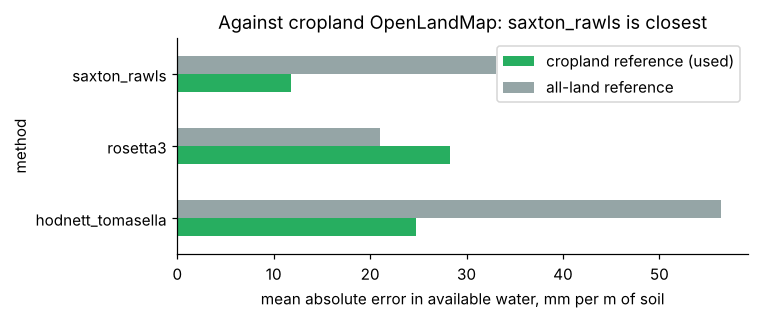

In [9]:
# Choose the method with the lowest available-water error against the cropland reference,
# averaged over both layers. The chart shows how the all-land reference would rank them.
awc_mae = (
    scores[(scores["quantity"] == "awc") & (scores["reference"] == "cropland")]
    .groupby("method")["mae"]
    .mean()
    .sort_values()
)
awc_mae_all_land = (
    scores[(scores["quantity"] == "awc") & (scores["reference"] == "all_land")]
    .groupby("method")["mae"]
    .mean()
)
chosen = awc_mae.index[0]
fig, ax = plt.subplots(figsize=(7, 3))
pd.DataFrame({"cropland reference (used)": awc_mae, "all-land reference": awc_mae_all_land}).mul(
    1000
).plot.barh(ax=ax, color=["#27ae60", "#95a5a6"])
ax.set_xlabel("mean absolute error in available water, mm per m of soil")
ax.set_title(f"Against cropland OpenLandMap: {chosen} is closest")
plt.tight_layout()
scores[scores["reference"] == "cropland"].pivot_table(
    index=["quantity", "layer"], columns="method", values="bias"
).round(3)

**Reading.** The choice depends on matching the land: against cropland, Saxton-Rawls is closest; against all land, Rosetta3 would win because it holds the most water. The cropland match is the right comparison, since iSDA describes cropland. Its weak link is the scaled wilting point; a cropland-masked 1500 kPa pull would remove that assumption.

## 5. Below 50 cm: is extending the 20-50 cm layer downward reasonable?

In [10]:
# Check A9's assumption that soil below 50 cm holds about as much water as 20 to 50 cm.
deep = reference_layer(50, 100)["cropland"]
pd.DataFrame(
    {
        "OpenLandMap available water 20-50 cm": ref["20_50"]["awc"],
        "OpenLandMap available water 50-100 cm": deep["awc"],
    }
).mul(1000).describe().round(1)

,OpenLandMap available water 20-50 cm,OpenLandMap available water 50-100 cm
count,23.0,23.0
mean,111.6,103.4
std,11.5,11.6
min,93.2,83.8
25%,99.7,91.1
50%,114.5,103.3
75%,119.5,113.8
max,130.0,121.3


A9 extends the 20-50 cm value down to the rooting depth because iSDA stops at 50 cm. If OpenLandMap's 50-100 cm layer holds about the same water as its 20-50 cm layer, that extension is reasonable.

## 6. Save the chosen soil water for A9, all methods for the record, and log the run

In [11]:
# Save the chosen method's soil water for A9, every method's numbers and scores for the
# record, and the summary, then log one experiment row per method.
out = cfg.paths.output_dir / "a8"
chosen_wide = predicted[predicted["method"] == chosen].pivot(
    index="lga", columns="layer", values=["fc", "wp", "awc_mm_per_m"]
)
chosen_wide.columns = [
    f"{q}_{layer}cm" if q != "awc_mm_per_m" else f"awc_mm_per_m_{layer}cm"
    for q, layer in chosen_wide.columns
]
chosen_wide = chosen_wide.reset_index().assign(method=chosen)
write_csv(chosen_wide, cfg.paths.soil)
write_csv(predicted, out / "a8_lga_soil_water_all_methods.csv")
write_csv(scores, out / "a8_method_scores.csv")
summary = {
    "chosen": chosen,
    "reference": "OpenLandMap cropland (wilting point scaled)",
    "awc_mae_mm_per_m": awc_mae.mul(1000).round(1).to_dict(),
    "awc_mae_mm_per_m_all_land": awc_mae_all_land.mul(1000).round(1).to_dict(),
    "chosen_awc_mm_per_m": chosen_wide.filter(like="awc").mean().round(1).to_dict(),
}
write_json(summary, out / "a8_summary.json")
log_experiments(cfg.paths.experiment_log, experiments.a8_rows(scores, chosen, experiments.today()))
summary

{'chosen': 'saxton_rawls',
 'reference': 'OpenLandMap cropland (wilting point scaled)',
 'awc_mae_mm_per_m': {'saxton_rawls': 11.8,
  'hodnett_tomasella': 24.8,
  'rosetta3': 28.3},
 'awc_mae_mm_per_m_all_land': {'hodnett_tomasella': 56.4,
  'rosetta3': 21.0,
  'saxton_rawls': 33.0},
 'chosen_awc_mm_per_m': {'awc_mm_per_m_0_20cm': 113.5,
  'awc_mm_per_m_20_50cm': 120.3}}